# 05 — WaveDetect complementarity on unseen Claude

This notebook reproduces the paper's exact 20-split Ghostbuster complementarity experiment using the freshly recomputed measurements:

- \(W\): WaveDetect score, with predicted AI probability clipped to \([10^{-6}, 1-10^{-6}]\) and converted to a logit;
- \(C=(U(32),U(128),U(256))\): context utility;
- \(F\): recurrence frontloading;
- \(R=(R_{\mathrm{near}},R_{\mathrm{far}})\): richer two-dimensional recurrence-summary robustness block.

Because \(F=R_{\mathrm{near}}-R_{\mathrm{far}}\) exactly, including \(F\) together with \(R_{\mathrm{near}}\) and \(R_{\mathrm{far}}\) would be linearly redundant for the logistic meta-classifier.

The historical artifacts are used only to recover the exact document-selection and WaveDetect-availability masks used by the reported experiment. Historical feature values are never used for model fitting.

Protocol:

1. preserve the historical 9000-document manifest ordering;
2. recover the historical 7257-document auxiliary-feature selection;
3. recover the historical 7229-document WaveDetect availability mask;
4. for each seed \(0,\ldots,19\), permute the full 6000-item original GPT/human pool and split it 80/20;
5. intersect feature availability only after the split;
6. train a balanced logistic regression with train-only standardization;
7. evaluate on all available unseen-Claude documents plus held-out original humans;
8. compute within-seed deltas relative to the \(W\) baseline.

The 20 splits overlap and are interpreted as split-robustness checks, not independent replications.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
)

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
PROJECT_ROOT = ROOT.parent

DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

print("reproduction root:", ROOT)
print("project root:", PROJECT_ROOT)

reproduction root: ..
project root: /home/user/Downloads/TemporalContextResearch


## Inputs

Fresh measurements come from notebooks `00a`, `00b`, and `00d`. The historical project contributes only the exact protocol masks/order needed to reproduce the already-reported detector experiment.

In [2]:
RAW_POOL_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS / "ghostbuster_detector_context.parquet"
F_PATH = RESULTS / "ghostbuster_detector_frontloading.parquet"
W_PATH = RESULTS / "wavedetect_scores.parquet"

HIST_AUG_DIR = PROJECT_ROOT / "results" / "ghostbuster_augmentation"
HIST_MANIFEST_PATH = HIST_AUG_DIR / "augmentation_manifest.parquet"
HIST_SELECTION_PATH = HIST_AUG_DIR / "ghostbuster_context_features.parquet"

HIST_WAVE_PATH = (
    PROJECT_ROOT
    / "results"
    / "wavedetect_comparison"
    / "wavedetect_scores.parquet"
)

required = [
    RAW_POOL_PATH,
    CTX_PATH,
    F_PATH,
    W_PATH,
    HIST_MANIFEST_PATH,
    HIST_SELECTION_PATH,
    HIST_WAVE_PATH,
]

for p in required:
    assert p.exists(), f"Missing required input: {p}"

print("All required inputs found.")

All required inputs found.


## Normalize Ghostbuster document identity

Historical artifacts store absolute paths under `ghostbuster-data-paper/`; the reproduction pool stores Ghostbuster-relative paths. We reduce both to the same relative identity.

In [3]:
def normalize_file(x):
    x = str(x).replace("\\", "/")

    for marker in [
        "ghostbuster-data-paper/",
        "ghostbuster-data/",
    ]:
        if marker in x:
            return x.split(marker, 1)[1]

    return x

## Load the historical protocol masks

The historical augmentation manifest contains 9000 documents: 6000 original GPT/human documents and 3000 Claude evaluation documents.

The historical auxiliary-feature table defines the exact 7257-document selection used by the reported analysis. The historical WaveDetect artifact defines the exact 7229-document availability mask.

In [4]:
hist_manifest = pd.read_parquet(HIST_MANIFEST_PATH).copy()
hist_selection = pd.read_parquet(HIST_SELECTION_PATH).copy()
hist_wave = pd.read_parquet(HIST_WAVE_PATH).copy()

hist_manifest["rel_file"] = hist_manifest["file"].map(normalize_file)
hist_selection["rel_file"] = hist_selection["file"].map(normalize_file)
hist_wave["rel_file"] = hist_wave["file"].map(normalize_file)

assert len(hist_manifest) == 9000
assert hist_manifest["rel_file"].nunique() == 9000

selected_files = set(hist_selection["rel_file"])
wave_available_files = set(hist_wave["rel_file"])

assert len(selected_files) == 7257
assert len(wave_available_files) == 7229
assert wave_available_files <= selected_files

if "source" not in hist_manifest.columns:
    hist_manifest["source"] = np.where(
        hist_manifest["generator"].eq("claude"),
        "claude_eval",
        "original",
    )

original_manifest = (
    hist_manifest[hist_manifest["source"] == "original"]
    .reset_index(drop=True)
    .copy()
)

claude_manifest = (
    hist_manifest[hist_manifest["source"] == "claude_eval"]
    .reset_index(drop=True)
    .copy()
)

assert len(original_manifest) == 6000
assert len(claude_manifest) == 3000

print("historical manifest:", len(hist_manifest))
print("auxiliary-feature selection:", len(selected_files))
print("WaveDetect availability:", len(wave_available_files))
print("original pool:", len(original_manifest))
print("Claude evaluation pool:", len(claude_manifest))

historical manifest: 9000
auxiliary-feature selection: 7257
WaveDetect availability: 7229
original pool: 6000
Claude evaluation pool: 3000


## Load freshly recomputed \(C\), \(F\), and \(W\)

All classifier feature values below come from the reproduction outputs, not from historical feature files.

In [5]:
raw = pd.read_parquet(RAW_POOL_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()
front = pd.read_parquet(F_PATH).copy()
wave = pd.read_parquet(W_PATH).copy()

raw["rel_file"] = raw["file"].map(normalize_file)

for name, df in {
    "raw": raw,
    "context": ctx,
    "frontloading": front,
    "WaveDetect": wave,
}.items():
    assert df["row_id"].nunique() == 9000, f"{name}: row_id mismatch"

assert raw["rel_file"].nunique() == 9000

fresh = (
    raw[
        [
            "row_id",
            "rel_file",
            "source",
            "domain",
            "generator",
            "label",
        ]
    ]
    .merge(
        ctx[
            [
                "row_id",
                "context_u_32",
                "context_u_128",
                "context_u_256",
            ]
        ],
        on="row_id",
        validate="one_to_one",
    )
    .merge(
        front[
            [
                "row_id",
                "near_token_cache",
                "far_token_cache",
                "token_frontloading",
            ]
        ],
        on="row_id",
        validate="one_to_one",
    )
    .merge(
        wave[
            [
                "row_id",
                "wave_ai_score",
            ]
        ],
        on="row_id",
        validate="one_to_one",
    )
)

assert len(fresh) == 9000

fresh["in_historical_selection"] = fresh["rel_file"].isin(selected_files)
fresh["wave_historically_available"] = fresh["rel_file"].isin(wave_available_files)

selected = fresh[fresh["in_historical_selection"]].copy()
assert len(selected) == 7257

print("fresh rows in exact historical selection:", len(selected))
print(
    selected[
        [
            "context_u_32",
            "context_u_128",
            "context_u_256",
            "near_token_cache",
            "far_token_cache",
            "token_frontloading",
            "wave_ai_score",
        ]
    ].isna().sum()
)

fresh rows in exact historical selection: 7257
context_u_32          0
context_u_128         0
context_u_256         0
near_token_cache      1
far_token_cache       1
token_frontloading    1
wave_ai_score         0
dtype: int64


## Feature blocks

WaveDetect probability \(p\) is transformed as

\[
W=\log\frac{p}{1-p},
\]

after clipping to \([10^{-6},1-10^{-6}]\).

In [6]:
EPS = 1e-6

p = np.clip(
    selected["wave_ai_score"].astype(float),
    EPS,
    1 - EPS,
)

selected["wave_logit"] = np.log(p / (1 - p))

C = [
    "context_u_32",
    "context_u_128",
    "context_u_256",
]

F = [
    "token_frontloading",
]

R = [
    "near_token_cache",
    "far_token_cache",
    "token_frontloading",
]

FEATURE_SETS = {
    "W": ["wave_logit"],
    "W+C": ["wave_logit"] + C,
    "W+F": ["wave_logit"] + F,
    "W+C+F": ["wave_logit"] + C + F,
    "W+R": ["wave_logit"] + R,
    "W+C+R": ["wave_logit"] + C + R,
}

FEATURE_SETS

{'W': ['wave_logit'],
 'W+C': ['wave_logit', 'context_u_32', 'context_u_128', 'context_u_256'],
 'W+F': ['wave_logit', 'token_frontloading'],
 'W+C+F': ['wave_logit',
  'context_u_32',
  'context_u_128',
  'context_u_256',
  'token_frontloading'],
 'W+R': ['wave_logit',
  'near_token_cache',
  'far_token_cache',
  'token_frontloading'],
 'W+C+R': ['wave_logit',
  'context_u_32',
  'context_u_128',
  'context_u_256',
  'near_token_cache',
  'far_token_cache',
  'token_frontloading']}

## Evaluation helpers

In [7]:
def tpr_at_fpr(y_true, scores, target=0.01):
    fpr, tpr, _ = roc_curve(y_true, scores)
    valid = np.where(fpr <= target)[0]
    return 0.0 if len(valid) == 0 else float(np.max(tpr[valid]))


def evaluate(y_true, scores):
    pred = (scores >= 0.5).astype(int)

    return {
        "accuracy": accuracy_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "auroc": roc_auc_score(y_true, scores),
        "auprc": average_precision_score(y_true, scores),
        "tpr_at_1fpr": tpr_at_fpr(y_true, scores, target=0.01),
    }

## Exact 20-split experiment

For each seed, the permutation and 80/20 split are applied to the **full 6000-item original manifest first**. Only afterward are the historical selection mask, historical WaveDetect availability mask, and requested feature non-missingness applied.

Evaluation contains all available Claude rows plus the human portion of the held-out original split.

In [8]:
rows = []

feature_table_base = selected[
    [
        "rel_file",
        "wave_historically_available",
        "wave_logit",
        *C,
        "near_token_cache",
        "far_token_cache",
        "token_frontloading",
    ]
].copy()

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(original_manifest))
    split = int(0.8 * len(original_manifest))

    train_full = original_manifest.iloc[perm[:split]].copy()
    test_full = original_manifest.iloc[perm[split:]].copy()

    heldout_human = test_full[
        test_full["generator"] == "human"
    ].copy()

    eval_full = pd.concat(
        [
            claude_manifest,
            heldout_human,
        ],
        ignore_index=True,
    )

    for method, cols in FEATURE_SETS.items():
        train = (
            train_full[
                [
                    "rel_file",
                    "label",
                    "generator",
                ]
            ]
            .merge(
                feature_table_base[
                    [
                        "rel_file",
                        "wave_historically_available",
                        *cols,
                    ]
                ],
                on="rel_file",
                how="inner",
                validate="one_to_one",
            )
        )

        test = (
            eval_full[
                [
                    "rel_file",
                    "label",
                    "generator",
                ]
            ]
            .merge(
                feature_table_base[
                    [
                        "rel_file",
                        "wave_historically_available",
                        *cols,
                    ]
                ],
                on="rel_file",
                how="inner",
                validate="one_to_one",
            )
        )

        # Historical WaveDetect availability is intersected only after the split.
        train = (
            train[train["wave_historically_available"]]
            .dropna(subset=cols)
            .copy()
        )

        test = (
            test[test["wave_historically_available"]]
            .dropna(subset=cols)
            .copy()
        )

        X_train = train[cols].to_numpy(float)
        y_train = train["label"].to_numpy(int)

        X_test = test[cols].to_numpy(float)
        y_test = test["label"].to_numpy(int)

        scaler = StandardScaler()
        X_train_z = scaler.fit_transform(X_train)
        X_test_z = scaler.transform(X_test)

        clf = LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=0,
        )

        clf.fit(X_train_z, y_train)
        score = clf.predict_proba(X_test_z)[:, 1]

        rows.append(
            {
                "seed": seed,
                "method": method,
                "n_train": len(train),
                "n_test": len(test),
                **evaluate(y_test, score),
            }
        )

results = pd.DataFrame(rows)

RESULT_PATH = RESULTS / "wavedetect_exact20_results.csv"
results.to_csv(RESULT_PATH, index=False)

print("saved:", RESULT_PATH)
display(results.head(12))

saved: ../results/wavedetect_exact20_results.csv


,seed,method,n_train,n_test,accuracy,f1,auroc,auprc,tpr_at_1fpr
0,0,W,4046,3183,0.674207,0.765332,0.965037,0.991005,0.454512
1,0,W+C,4046,3183,0.682061,0.772380,0.965369,0.991757,0.499079
2,0,W+F,4046,3183,0.690544,0.779494,0.969885,0.991487,0.484715
3,0,W+C+F,4046,3183,0.696513,0.784279,0.969923,0.991995,0.559484
4,0,W+R,4046,3183,0.694942,0.783211,0.970141,0.991191,0.466667
5,0,W+C+R,4046,3183,0.704681,0.791482,0.970237,0.991838,0.525967
6,1,W,3615,3200,0.678750,0.769196,0.945477,0.984454,0.126703
7,1,W+C,3615,3200,0.685000,0.774698,0.947670,0.985932,0.177164
8,1,W+F,3615,3200,0.703125,0.790564,0.949011,0.985865,0.176427
9,1,W+C+F,3615,3200,0.705313,0.792336,0.951017,0.986847,0.212523


## Within-seed deltas against \(W\)

Every augmentation is compared against the \(W\)-only result from the same split.

In [9]:
METRICS = [
    "accuracy",
    "f1",
    "auroc",
    "auprc",
    "tpr_at_1fpr",
]

baseline = (
    results[results["method"] == "W"]
    .set_index("seed")
)

delta_rows = []

for _, row in results.iterrows():
    if row["method"] == "W":
        continue

    base = baseline.loc[row["seed"]]

    out = {
        "seed": int(row["seed"]),
        "method": row["method"],
    }

    for metric in METRICS:
        out[f"delta_{metric}"] = (
            row[metric] - base[metric]
        )

    delta_rows.append(out)

deltas = pd.DataFrame(delta_rows)

DELTA_PATH = RESULTS / "wavedetect_exact20_deltas.csv"
deltas.to_csv(DELTA_PATH, index=False)

print("saved:", DELTA_PATH)
display(deltas.head(10))

saved: ../results/wavedetect_exact20_deltas.csv


,seed,method,delta_accuracy,delta_f1,delta_auroc,delta_auprc,delta_tpr_at_1fpr
0,0,W+C,0.007854,0.007048,0.000332,0.000752,0.044567
1,0,W+F,0.016337,0.014163,0.004848,0.000482,0.030203
2,0,W+C+F,0.022306,0.018947,0.004886,0.000991,0.104972
3,0,W+R,0.020735,0.017879,0.005105,0.000187,0.012155
4,0,W+C+R,0.030474,0.026150,0.005200,0.000833,0.071455
5,1,W+C,0.006250,0.005502,0.002192,0.001478,0.050460
6,1,W+F,0.024375,0.021368,0.003534,0.001411,0.049724
7,1,W+C+F,0.026563,0.023140,0.005539,0.002392,0.085820
8,1,W+R,0.021875,0.019325,0.004131,0.001785,0.074401
9,1,W+C+R,0.026875,0.023406,0.006284,0.002806,0.067403


## Split-robustness summary

In [10]:
SUMMARY_METHODS = [
    "W+C",
    "W+F",
    "W+C+F",
    "W+R",
    "W+C+R",
]

SUMMARY_METRICS = [
    "f1",
    "auroc",
    "auprc",
    "tpr_at_1fpr",
]

summary_rows = []

for method in SUMMARY_METHODS:
    d = deltas[deltas["method"] == method]

    out = {
        "method": method,
        "n_splits": len(d),
    }

    for metric in SUMMARY_METRICS:
        col = f"delta_{metric}"

        out[f"mean_{col}"] = d[col].mean()
        out[f"positive_{col}"] = int((d[col] > 0).sum())
        out[f"min_{col}"] = d[col].min()
        out[f"max_{col}"] = d[col].max()

    summary_rows.append(out)

summary = pd.DataFrame(summary_rows)

SUMMARY_PATH = RESULTS / "wavedetect_exact20_summary.csv"
summary.to_csv(SUMMARY_PATH, index=False)

print("saved:", SUMMARY_PATH)

display(
    summary[
        [
            "method",
            "mean_delta_auroc",
            "positive_delta_auroc",
            "mean_delta_tpr_at_1fpr",
            "positive_delta_tpr_at_1fpr",
            "mean_delta_f1",
            "positive_delta_f1",
            "mean_delta_auprc",
            "positive_delta_auprc",
        ]
    ]
)

saved: ../results/wavedetect_exact20_summary.csv


,method,mean_delta_auroc,positive_delta_auroc,mean_delta_tpr_at_1fpr,positive_delta_tpr_at_1fpr,mean_delta_f1,positive_delta_f1,mean_delta_auprc,positive_delta_auprc
0,W+C,0.000975,18,0.020737,16,0.005896,20,0.000793,20
1,W+F,0.004172,20,0.034457,15,0.016590,20,0.001365,19
2,W+C+F,0.004984,20,0.071786,20,0.019996,20,0.001925,20
3,W+R,0.004705,20,0.043039,17,0.017567,20,0.001477,19
4,W+C+R,0.005588,20,0.073444,20,0.024456,20,0.002056,20


## Headline figure

The main paper comparison is \(W+C\), \(W+F\), and \(W+C+F\). The richer recurrence block is retained in the saved tables as a robustness reference.

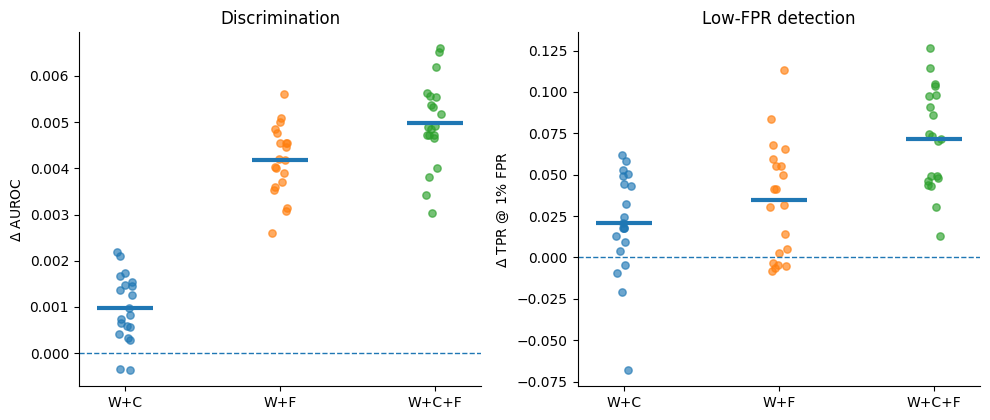

saved: ../figures/wavedetect_exact20_complementarity.pdf
saved: ../figures/wavedetect_exact20_complementarity.png


In [11]:
plot_methods = [
    "W+C",
    "W+F",
    "W+C+F",
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4.3),
)

specs = [
    (
        "delta_auroc",
        r"$\Delta$ AUROC",
        "Discrimination",
    ),
    (
        "delta_tpr_at_1fpr",
        r"$\Delta$ TPR @ 1% FPR",
        "Low-FPR detection",
    ),
]

jitter_rng = np.random.default_rng(123)

for ax, (metric, ylabel, title) in zip(axes, specs):
    for i, method in enumerate(plot_methods):
        vals = deltas.loc[
            deltas["method"] == method,
            metric,
        ].to_numpy()

        jitter = jitter_rng.uniform(
            -0.055,
            0.055,
            len(vals),
        )

        ax.scatter(
            i + jitter,
            vals,
            alpha=0.65,
            s=28,
        )

        ax.hlines(
            vals.mean(),
            i - 0.18,
            i + 0.18,
            linewidth=3,
        )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1,
    )

    ax.set_xticks(
        range(len(plot_methods))
    )
    ax.set_xticklabels(
        plot_methods
    )
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()

PDF_PATH = FIGURES / "wavedetect_exact20_complementarity.pdf"
PNG_PATH = FIGURES / "wavedetect_exact20_complementarity.png"

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
)

fig.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("saved:", PDF_PATH)
print("saved:", PNG_PATH)

## Expected reproduction check

The previously reported headline values were approximately:

- \(W+C+F\): mean \(\Delta\)AUROC \(=+0.00499\);
- \(W+C+F\): mean \(\Delta\)TPR@1%FPR \(=+0.0715\);
- \(W+C+F\): mean \(\Delta\)F1 \(=+0.0220\);
- \(W+C+F\): mean \(\Delta\)AUPRC \(=+0.00193\).

The AUROC, TPR@1%FPR, F1, and AUPRC gains were positive in all 20 splits.

For the richer recurrence robustness block, \(W+C+R\) previously gave approximately \(+0.00560\) mean AUROC and \(+0.0735\) mean TPR@1%FPR.

In [12]:
headline = summary[
    summary["method"].isin(
        [
            "W+C",
            "W+F",
            "W+C+F",
            "W+C+R",
        ]
    )
][
    [
        "method",
        "mean_delta_auroc",
        "positive_delta_auroc",
        "mean_delta_tpr_at_1fpr",
        "positive_delta_tpr_at_1fpr",
        "mean_delta_f1",
        "positive_delta_f1",
        "mean_delta_auprc",
        "positive_delta_auprc",
    ]
]

display(headline)

,method,mean_delta_auroc,positive_delta_auroc,mean_delta_tpr_at_1fpr,positive_delta_tpr_at_1fpr,mean_delta_f1,positive_delta_f1,mean_delta_auprc,positive_delta_auprc
0,W+C,0.000975,18,0.020737,16,0.005896,20,0.000793,20
1,W+F,0.004172,20,0.034457,15,0.016590,20,0.001365,19
2,W+C+F,0.004984,20,0.071786,20,0.019996,20,0.001925,20
4,W+C+R,0.005588,20,0.073444,20,0.024456,20,0.002056,20
